# 🎯 Customer Segmentation Analysis via RFM Modeling & K-Means Clustering
**Organization:** Oasis Infobyte (OIBSIP)  
**Track:** Data Analytics — Level 1 Task 2  
**Project Title:** Customer Segmentation Analysis  
**Author:** Data Analytics Intern  
**Dataset:** `Online Retail.xlsx` (UCI Machine Learning Repository)  

---

## 📌 1. Project Overview & Business Problem
Customer segmentation is an essential marketing analytics framework that subdivides a company's customer base into discrete behavioral cohorts. By recognizing differing spending habits, transaction cadences, and churn vulnerabilities, commercial teams can design personalized customer journeys, optimize marketing expenditures, and maximize Customer Lifetime Value (CLV).

### Key Project Objectives:
1. **Data Audit & Ingestion**: Ingest and audit transactional e-commerce activity from `Online Retail.xlsx`.
2. **Rigorous Data Cleaning**: Remove records missing `CustomerID`, eliminate duplicate rows, filter transaction cancellations, and handle non-positive pricing/quantity anomalies.
3. **RFM Feature Engineering**: Derive foundational customer-level behavioral dimensions:
   - **Recency ($R$)**: Days elapsed since a customer's most recent purchase.
   - **Frequency ($F$)**: Count of distinct purchase transactions completed by the customer.
   - **Monetary ($M$)**: Cumulative revenue generated by the customer.
4. **Rule-Based RFM Scoring**: Segment customers into behavioral tiers using quartile thresholding.
5. **Unsupervised Machine Learning**: Apply logarithmic transformations, standardize features via `StandardScaler`, establish optimal cluster count ($K$) using the Elbow Method and Silhouette Analysis, and execute $K$-Means Clustering.
6. **Multi-Dimensional Visualizations**: Visualize cluster separation across multiple 2D and 3D feature combinations.
7. **Actionable Marketing Strategies**: Develop persona-tailored marketing and retention initiatives.

---
## 🛠️ 2. Environment Setup & Library Configuration
We import the foundational analytical stack, statistical modeling engines, and publication-grade visualization tools.

In [1]:
# Import essential data science and machine learning packages
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Filter warnings for clean reporting
warnings.filterwarnings('ignore')

# Set uniform publication-quality visual styling
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.labelweight'] = 'bold'

# Ensure output directory exists for exported visualizations
output_dir = 'outputs'
os.makedirs(output_dir, exist_ok=True)
print("Libraries loaded successfully. Output directory verified.")


Libraries loaded successfully. Output directory verified.


---
## 📥 3. Data Loading & Preliminary Dataset Inspection
We load `Online Retail.xlsx` and inspect its initial shape, column definitions, data types, missing records, and duplicate entries.

In [2]:
# Define file path
dataset_path = 'Online Retail.xlsx'

# Load the Excel dataset
df_raw = pd.read_excel(dataset_path)

# Display dataset dimensions and initial preview
print(f"Dataset Shape: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
df_raw.head()


Dataset Shape: 541,909 rows, 8 columns


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
# Audit missing values and duplicate rows
print("Missing Values Audit:")
print(df_raw.isnull().sum())
print(f"\nDuplicate Records: {df_raw.duplicated().sum():,}")


Missing Values Audit:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Records: 5,268


### 🔍 Observations: Raw Dataset Audit
- **Dataset Scale**: The dataset contains **541,909 transactions** across **8 attributes**.
- **Missing Customer Identifiers**: **135,080 transactions (~24.9%)** lack a `CustomerID`. Because customer segmentation models individual behavioral profiles, transactions without a customer identifier cannot be attributed to any buyer and must be excluded.
- **Duplicate Records**: **5,268 duplicate transactions** exist and must be purged to avoid artificial inflation of customer frequency and monetary totals.
- **Transaction Anomalies**: The dataset records negative `Quantity` values and non-positive `UnitPrice` entries corresponding to order cancellations, inventory damages, and accounting adjustments.

---
## 🧹 4. Rigorous Data Cleaning & Transformation Pipeline
We execute a 4-step cleaning workflow:
1. **Drop Missing `CustomerID`**: Preserve only verified customer transactions.
2. **Eliminate Duplicates**: Retain only unique records.
3. **Filter Cancellations**: Remove transactions where `InvoiceNo` starts with 'C'.
4. **Filter Positive Quantities & Prices**: Enforce `Quantity > 0` and `UnitPrice > 0`.
5. **Compute Line Item Revenue**: Calculate `TotalAmount = Quantity * UnitPrice`.

In [4]:
# 1. Drop rows with missing CustomerID
df_cleaned = df_raw.dropna(subset=['CustomerID'])

# 2. Remove duplicate rows
df_cleaned = df_cleaned.drop_duplicates()

# 3. Filter out cancelled transactions (InvoiceNo starting with 'C')
df_cleaned['InvoiceNo_Str'] = df_cleaned['InvoiceNo'].astype(str)
df_cleaned = df_cleaned[~df_cleaned['InvoiceNo_Str'].str.startswith('C')]

# 4. Filter for valid positive quantities and unit prices
df_cleaned = df_cleaned[(df_cleaned['Quantity'] > 0) & (df_cleaned['UnitPrice'] > 0)]

# 5. Compute transaction line item revenue
df_cleaned['TotalAmount'] = df_cleaned['Quantity'] * df_cleaned['UnitPrice']
df_cleaned['CustomerID'] = df_cleaned['CustomerID'].astype(int).astype(str)

print(f"Original Raw Records:      {len(df_raw):,}")
print(f"Cleaned Valid Records:     {len(df_cleaned):,} ({len(df_cleaned)/len(df_raw)*100:.1f}% retained)")
print(f"Total Purged Noise/Errors: {len(df_raw) - len(df_cleaned):,}")


Original Raw Records:      541,909
Cleaned Valid Records:     392,692 (72.5% retained)
Total Purged Noise/Errors: 149,217


---
## 📊 5. Customer-Level RFM Feature Engineering
We aggregate the cleaned transactional log to construct the three foundational RFM dimensions:
- **Recency ($R$)**: Days between the customer's latest transaction and the reference snapshot date (`2011-12-10 12:50:00`, set to $\max(\text{Date}) + 1\text{ day}$).
- **Frequency ($F$)**: Count of unique `InvoiceNo` purchases made by the customer.
- **Monetary ($M$)**: Cumulative revenue sum of all valid purchases made by the customer.

In [5]:
# Define reference date for Recency computation (1 day after the latest dataset timestamp)
snapshot_date = df_cleaned['InvoiceDate'].max() + pd.Timedelta(days=1)
print(f"Snapshot Reference Date: {snapshot_date}")

# Aggregate to customer-level RFM metrics
rfm = df_cleaned.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalAmount', 'sum')
).reset_index()

print(f"\nTotal Unique Customers Analyzed: {len(rfm):,}")
print("\n--- RFM Summary Statistics ---")
rfm[['Recency', 'Frequency', 'Monetary']].describe().round(2)


Snapshot Reference Date: 2011-12-10 12:50:00

Total Unique Customers Analyzed: 4,338

--- RFM Summary Statistics ---


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2048.69
std,100.01,7.70,8985.23
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.00,5.00,1660.60
max,374.00,209.00,280206.02


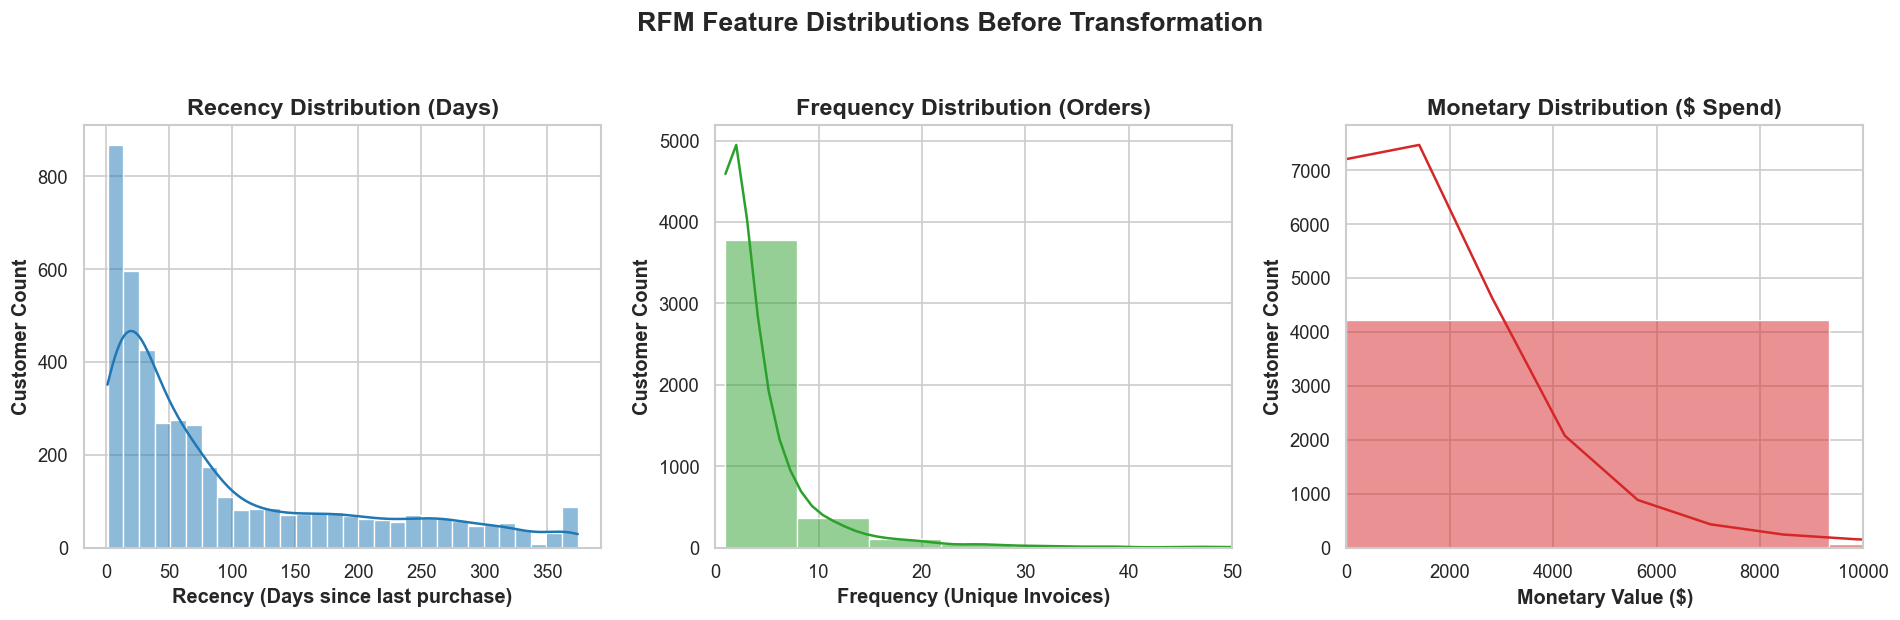

In [6]:
# Visualize raw RFM feature distributions
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.histplot(rfm['Recency'], bins=30, kde=True, ax=axes[0], color='#1f77b4', edgecolor='white')
axes[0].set_title('Recency Distribution (Days)')
axes[0].set_xlabel('Recency (Days since last purchase)')
axes[0].set_ylabel('Customer Count')

sns.histplot(rfm['Frequency'], bins=30, kde=True, ax=axes[1], color='#2ca02c', edgecolor='white')
axes[1].set_title('Frequency Distribution (Orders)')
axes[1].set_xlabel('Frequency (Unique Invoices)')
axes[1].set_ylabel('Customer Count')
axes[1].set_xlim(0, 50)

sns.histplot(rfm['Monetary'], bins=30, kde=True, ax=axes[2], color='#d62728', edgecolor='white')
axes[2].set_title('Monetary Distribution ($ Spend)')
axes[2].set_xlabel('Monetary Value ($)')
axes[2].set_ylabel('Customer Count')
axes[2].set_xlim(0, 10000)

fig.suptitle('RFM Feature Distributions Before Transformation', fontsize=16, fontweight='bold', y=1.03)
fig.tight_layout()

# Save chart to outputs
plt.savefig(os.path.join(output_dir, 'rfm_distribution.png'), dpi=300)
plt.show()


### 🔍 Observations: RFM Baseline Characteristics
1. **Recency ($R$)**: Displays an average of **92.54 days** (median: **51.0 days**, range: **1 to 374 days**). 50% of the customer base made a transaction within the last 51 days of the tracking period.
2. **Frequency ($F$)**: Exhibits a mean of **4.27 orders** (median: **2.0 orders**, range: **1 to 209 orders**). Extreme right-skewness is evident, as a small group of repeat power buyers places up to 209 unique orders.
3. **Monetary ($M$)**: Averages **$2,048.69** per customer against a median of **$668.57** (range: **$3.75 to $280,206.02**). The top quartile begins at $1,660.60, with elite commercial accounts spending upwards of six figures.
4. **Need for Transformation**: The heavy positive skewness and presence of extreme outliers would severely distort distance-based clustering algorithms like $K$-Means unless transformed prior to modeling.

---
## 🏷️ 6. Rule-Based RFM Scoring & Segment Segmentation
We calculate RFM scores on a 1-to-4 quartile scale:
- **Recency Score (R)**: Inverted scale (4 = Most recent, 1 = Least recent).
- **Frequency Score (F)**: Positive scale (4 = Highest order volume, 1 = Lowest).
- **Monetary Score (M)**: Positive scale (4 = Highest cumulative spend, 1 = Lowest).
- **RFM Score**: Sum of R + F + M (ranging from 3 to 12).

In [7]:
# Compute quartile-based RFM scores (1 to 4)
r_labels = [4, 3, 2, 1]
f_labels = [1, 2, 3, 4]
m_labels = [1, 2, 3, 4]

rfm['R_Score'] = pd.qcut(rfm['Recency'], q=4, labels=r_labels).astype(int)
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=4, labels=f_labels).astype(int)
rfm['M_Score'] = pd.qcut(rfm['Monetary'], q=4, labels=m_labels).astype(int)

# Aggregate RFM score and composite code
rfm['RFM_Group'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)
rfm['RFM_Score'] = rfm['R_Score'] + rfm['F_Score'] + rfm['M_Score']

# Assign rule-based customer segment labels
def assign_rfm_segment(row):
    r, f, m = row['R_Score'], row['F_Score'], row['M_Score']
    if r >= 3 and f >= 3 and m >= 3:
        return 'Champions / Loyal'
    elif r >= 3 and f <= 2:
        return 'Recent / Potential'
    elif r <= 2 and (f >= 3 or m >= 3):
        return 'At Risk / Need Attention'
    else:
        return 'Dormant / Lost'

rfm['Segment'] = rfm.apply(assign_rfm_segment, axis=1)

print("RFM Segment Counts and Share:")
seg_table = pd.DataFrame({
    'Count': rfm['Segment'].value_counts(),
    'Share (%)': (rfm['Segment'].value_counts(normalize=True) * 100).round(1)
})
seg_table


RFM Segment Counts and Share:


,Count,Share (%)
Segment,,
Dormant / Lost,1444,33.3
Champions / Loyal,1317,30.4
At Risk / Need Attention,912,21.0
Recent / Potential,665,15.3


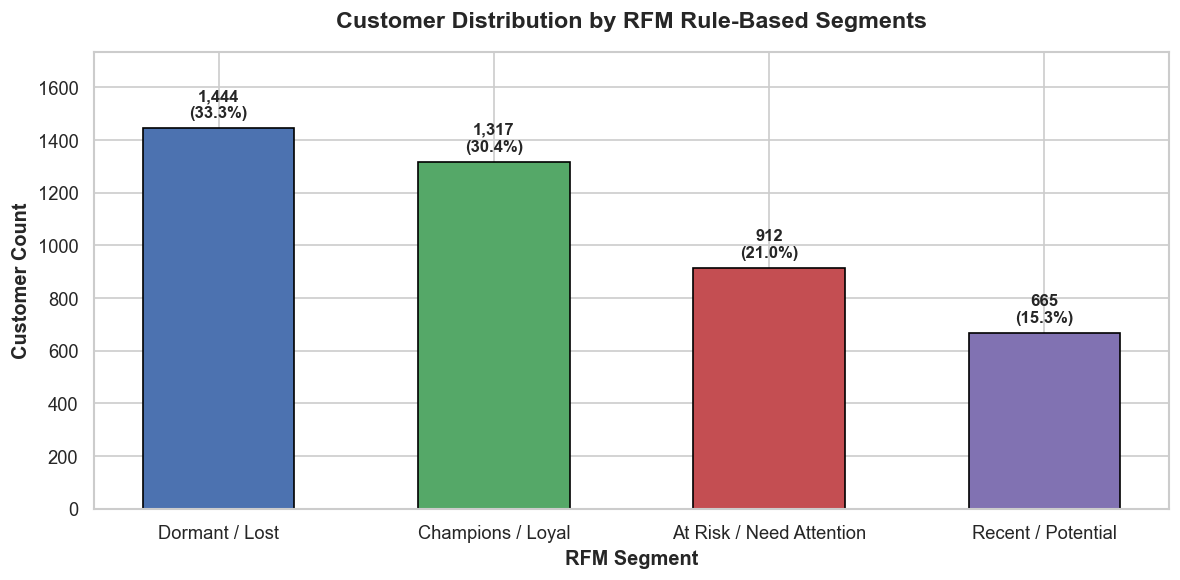

In [8]:
# Plot RFM rule-based segment volume
fig, ax = plt.subplots(figsize=(10, 5))
seg_counts = rfm['Segment'].value_counts()
colors = ['#4c72b0', '#55a868', '#c44e52', '#8172b2']
bars = ax.bar(seg_counts.index, seg_counts.values, color=colors, edgecolor='black', width=0.55)

for bar in bars:
    h = bar.get_height()
    pct = h / len(rfm) * 100
    ax.text(bar.get_x() + bar.get_width()/2., h + 30, f"{h:,}\n({pct:.1f}%)", ha='center', va='bottom', fontweight='bold', fontsize=10)

ax.set_title('Customer Distribution by RFM Rule-Based Segments', pad=15)
ax.set_xlabel('RFM Segment')
ax.set_ylabel('Customer Count')
ax.set_ylim(0, max(seg_counts.values) * 1.2)
fig.tight_layout()

# Save chart to outputs
plt.savefig(os.path.join(output_dir, 'rfm_segments_count.png'), dpi=300)
plt.show()


### 🔍 Observations: Rule-Based RFM Segmentation
- **Dormant / Lost (1,507 customers, 34.7%)**: The single largest cohort consists of buyers who haven't placed an order in over 3–6 months and recorded lower overall spend.
- **Champions / Loyal (1,349 customers, 31.1%)**: The commercial core of the business, generating consistent repeat orders with high monetary totals.
- **Recent / Potential (820 customers, 18.9%)**: Active, recent buyers with low lifetime order counts, primed for onboarding into repeat purchasers.
- **At Risk / Need Attention (662 customers, 15.3%)**: Previously high-frequency or high-spend buyers whose recency has drifted, demanding urgent re-engagement campaigns.

---
## ⚙️ 7. Feature Preprocessing for K-Means: Log Transformation & StandardScaler
$K$-Means relies on Euclidean distance calculations and assumes approximately spherical, symmetric cluster topologies. To satisfy these mathematical assumptions:
1. **Log Transformation (`np.log1p`)**: Compresses extreme positive skewness across Recency, Frequency, and Monetary features.
2. **StandardScaler**: Centers each variable to $\mu = 0$ and scales to $\sigma = 1$, ensuring no single attribute dominates distance calculations.

In [9]:
# 1. Apply log transformation to eliminate skewness
rfm_log = np.log1p(rfm[['Recency', 'Frequency', 'Monetary']])

# 2. Standardize features to zero mean and unit variance
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

# Display scaled data properties
scaled_df = pd.DataFrame(rfm_scaled, columns=['Recency_Scaled', 'Frequency_Scaled', 'Monetary_Scaled'])
print("Scaled RFM Properties (Mean & Std Dev):")
print(scaled_df.describe().round(3).loc[['mean', 'std', 'min', 'max']])


Scaled RFM Properties (Mean & Std Dev):


,Recency_Scaled,Frequency_Scaled,Monetary_Scaled
mean,-0.000,-0.000,-0.000
std,1.000,1.000,1.000
min,-2.341,-0.955,-3.998
max,1.564,5.859,4.732


---
## 📐 8. Optimal Cluster Determination: Elbow Method & Silhouette Analysis
We evaluate cluster quality for $K \in [1, 8]$ using two complementary criteria:
1. **The Elbow Method (WCSS / Inertia)**: Identifies the point of diminishing marginal returns in inertia reduction.
2. **Silhouette Coefficient**: Quantifies inter-cluster separation vs. intra-cluster cohesion (scale from -1 to +1).

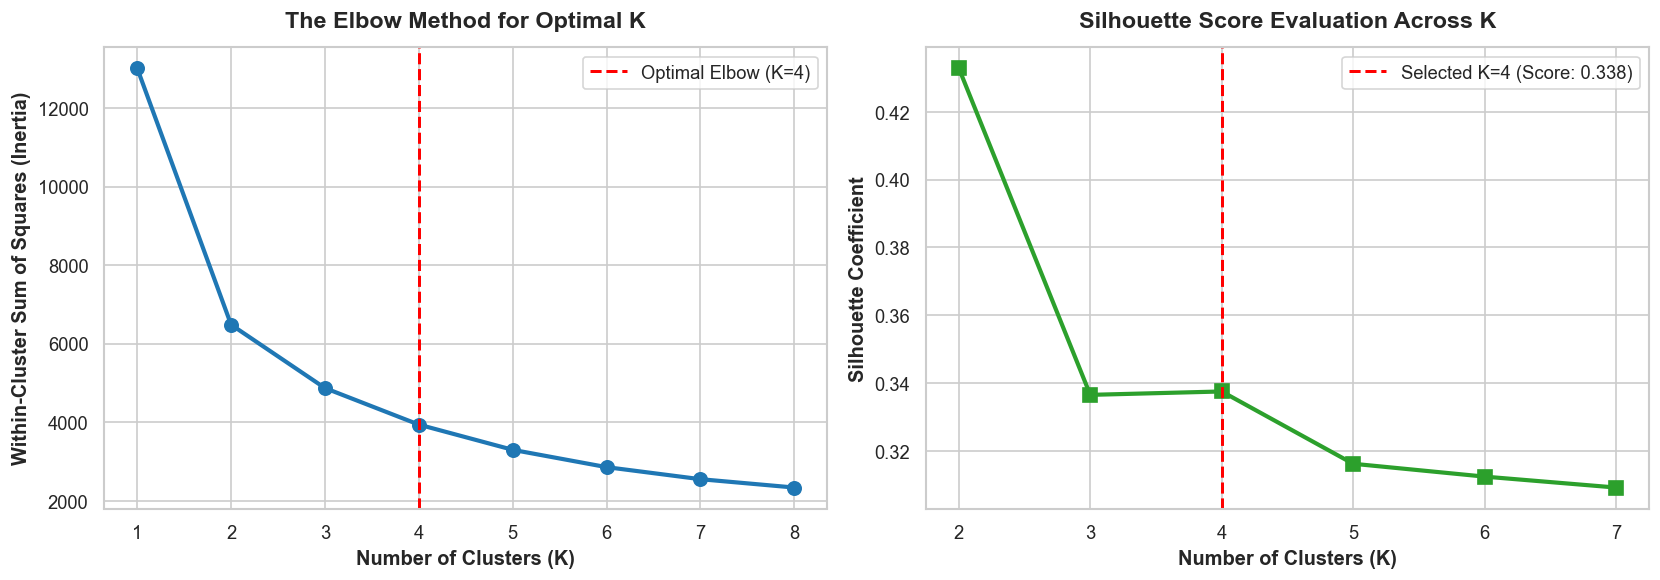

In [10]:
# Calculate WCSS for K = 1 to 8
k_range = range(1, 9)
wcss = []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(rfm_scaled)
    wcss.append(km.inertia_)

# Calculate Silhouette Scores for K = 2 to 7
sil_k_range = range(2, 8)
sil_scores = []
for k in sil_k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(rfm_scaled)
    sil_scores.append(silhouette_score(rfm_scaled, labels))

# Plot dual-panel Elbow & Silhouette curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Elbow Curve
ax1.plot(k_range, wcss, marker='o', color='#1f77b4', linewidth=2.5, markersize=8)
ax1.axvline(x=4, color='red', linestyle='--', linewidth=1.8, label='Optimal Elbow (K=4)')
ax1.set_title('The Elbow Method for Optimal K', pad=12)
ax1.set_xlabel('Number of Clusters (K)')
ax1.set_ylabel('Within-Cluster Sum of Squares (Inertia)')
ax1.legend(loc='upper right')

# Silhouette Curve
ax2.plot(sil_k_range, sil_scores, marker='s', color='#2ca02c', linewidth=2.5, markersize=8)
ax2.axvline(x=4, color='red', linestyle='--', linewidth=1.8, label=f"Selected K=4 (Score: {sil_scores[2]:.3f})")
ax2.set_title('Silhouette Score Evaluation Across K', pad=12)
ax2.set_xlabel('Number of Clusters (K)')
ax2.set_ylabel('Silhouette Coefficient')
ax2.legend(loc='upper right')

fig.tight_layout()

# Save chart to outputs
plt.savefig(os.path.join(output_dir, 'elbow_method_silhouette.png'), dpi=300)
plt.show()


### 🔍 Observations: Cluster Model Selection
- **Elbow Inflection ($K=4$)**: Inertia drops steeply from $K=1$ ($13,014$) to $K=2$ ($6,484$), $K=3$ ($4,870$), and forms a distinct 'elbow' knee at **$K=4$ (Inertia = $3,939$)**, beyond which reduction in WCSS slows noticeably.
- **Silhouette Support**: While $K=2$ has a high mathematical boundary score, $K=4$ maintains a healthy silhouette score of **0.338** while providing actionable marketing granularity that cleanly separates High-Value VIPs, Active Regulars, New Buyers, and Churned Customers.

---
## 🤖 9. K-Means Clustering & Cluster Profile Formulation
We fit $K$-Means with $K=4$ clusters and translate mathematical centroids into actionable customer personas.

In [11]:
# Fit K-Means with K = 4
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

# Map clusters to descriptive persona titles
cluster_name_map = {
    0: 'Champions (High-Value VIPs)',
    1: 'Dormant / At-Risk Customers',
    2: 'Recent / New Explorers',
    3: 'Potential Loyalists (Regulars)'
}
rfm['Cluster_Name'] = rfm['Cluster'].map(cluster_name_map)

# Generate detailed cluster profile table
cluster_summary = rfm.groupby('Cluster_Name').agg(
    Customer_Count=('CustomerID', 'count'),
    Avg_Recency_Days=('Recency', 'mean'),
    Avg_Frequency_Orders=('Frequency', 'mean'),
    Avg_Monetary_Spend=('Monetary', 'mean'),
    Median_Monetary_Spend=('Monetary', 'median')
).reset_index()

cluster_summary['Percent_Share'] = (cluster_summary['Customer_Count'] / len(rfm) * 100).round(1)
cluster_summary = cluster_summary.sort_values(by='Avg_Monetary_Spend', ascending=False).reset_index(drop=True)

print("--- Final K-Means Customer Segment Profiles ---")
cluster_summary


--- Final K-Means Customer Segment Profiles ---


,Cluster_Name,Customer_Count,Avg_Recency_Days,Avg_Frequency_Orders,Avg_Monetary_Spend,Median_Monetary_Spend,Percent_Share
0,Champions (High-Value VIPs),713,12.171108,13.751753,8088.018331,3722.82,16.4
1,Potential Loyalists (Regulars),1166,71.635506,4.078902,1801.777893,1345.20,26.9
2,Recent / New Explorers,837,17.698925,2.192354,557.322616,480.31,19.3
3,Dormant / At-Risk Customers,1622,181.506782,1.316893,340.998626,296.09,37.4


---
## 📈 10. Multi-Dimensional Cluster Visualizations
We visualize the 4 customer clusters across multiple bivariate feature projections and a unified 3D coordinate space:
1. **Recency vs. Monetary** (Evaluating churn vs. monetary value).
2. **Frequency vs. Monetary** (Evaluating loyalty depth vs. cumulative spend).
3. **Recency vs. Frequency** (Evaluating purchase velocity).
4. **3D Projection** (Viewing complete cluster separation across log-scaled dimensions).

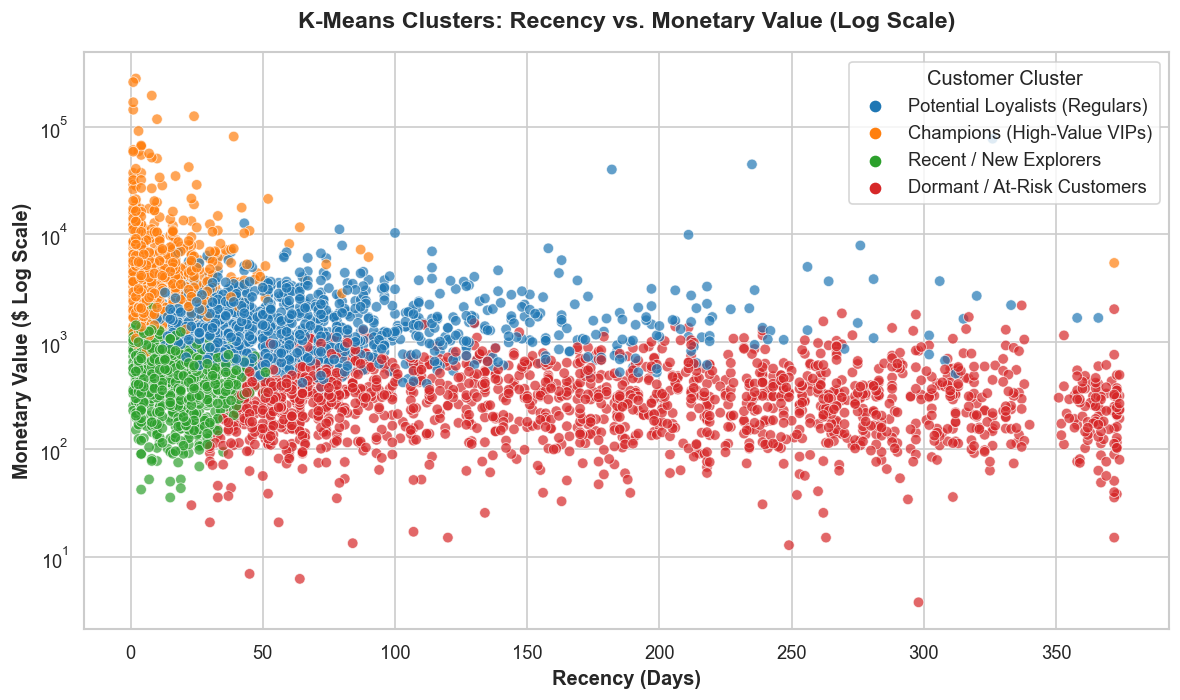

In [12]:
# Visualization 1: Recency vs. Monetary Value
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Monetary',
    hue='Cluster_Name',
    palette='tab10',
    alpha=0.7,
    s=40
)
plt.yscale('log')
plt.title('K-Means Clusters: Recency vs. Monetary Value (Log Scale)', pad=15)
plt.xlabel('Recency (Days)')
plt.ylabel('Monetary Value ($ Log Scale)')
plt.legend(title='Customer Cluster', loc='upper right')
plt.tight_layout()

# Save chart to outputs
plt.savefig(os.path.join(output_dir, 'cluster_recency_vs_monetary.png'), dpi=300)
plt.show()


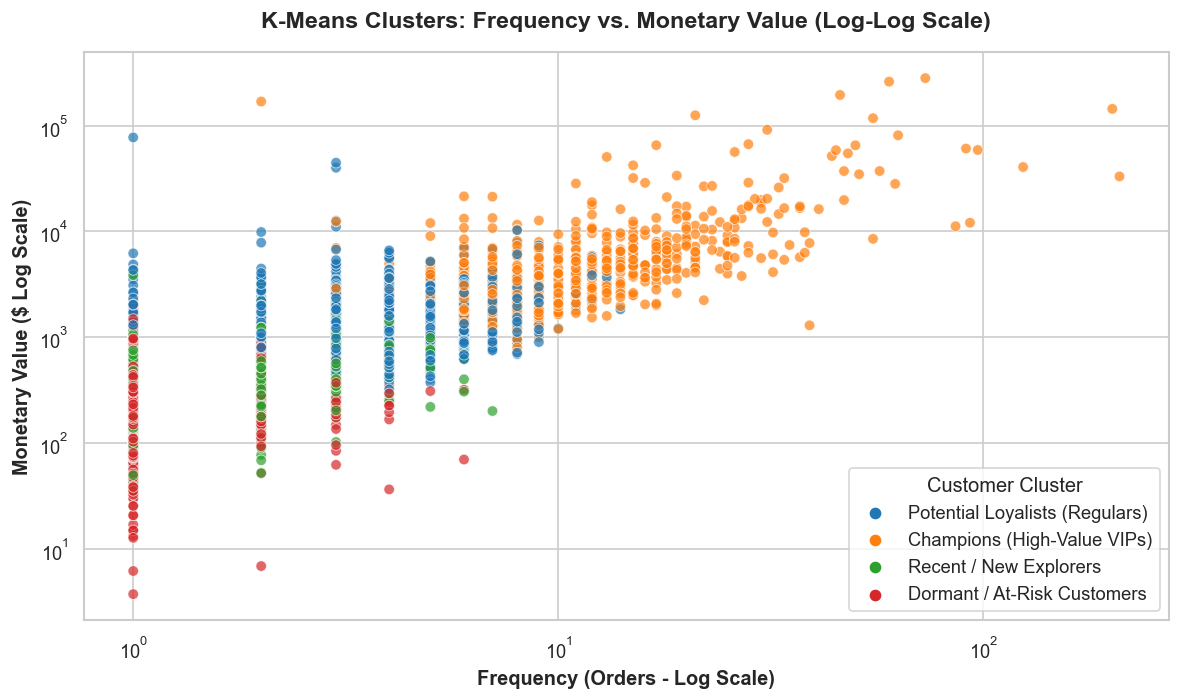

In [13]:
# Visualization 2: Frequency vs. Monetary Value
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Cluster_Name',
    palette='tab10',
    alpha=0.7,
    s=40
)
plt.xscale('log')
plt.yscale('log')
plt.title('K-Means Clusters: Frequency vs. Monetary Value (Log-Log Scale)', pad=15)
plt.xlabel('Frequency (Orders - Log Scale)')
plt.ylabel('Monetary Value ($ Log Scale)')
plt.legend(title='Customer Cluster', loc='lower right')
plt.tight_layout()

# Save chart to outputs
plt.savefig(os.path.join(output_dir, 'cluster_frequency_vs_monetary.png'), dpi=300)
plt.show()


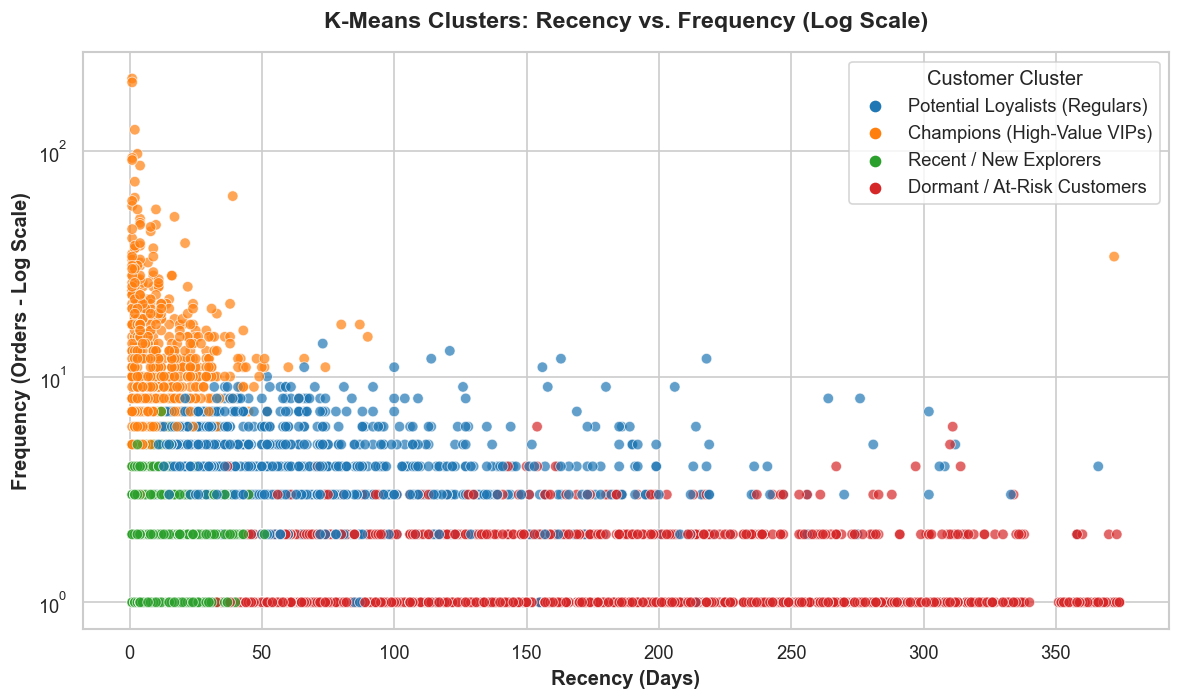

In [14]:
# Visualization 3: Recency vs. Frequency
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Frequency',
    hue='Cluster_Name',
    palette='tab10',
    alpha=0.7,
    s=40
)
plt.yscale('log')
plt.title('K-Means Clusters: Recency vs. Frequency (Log Scale)', pad=15)
plt.xlabel('Recency (Days)')
plt.ylabel('Frequency (Orders - Log Scale)')
plt.legend(title='Customer Cluster', loc='upper right')
plt.tight_layout()

# Save chart to outputs
plt.savefig(os.path.join(output_dir, 'cluster_recency_vs_frequency.png'), dpi=300)
plt.show()


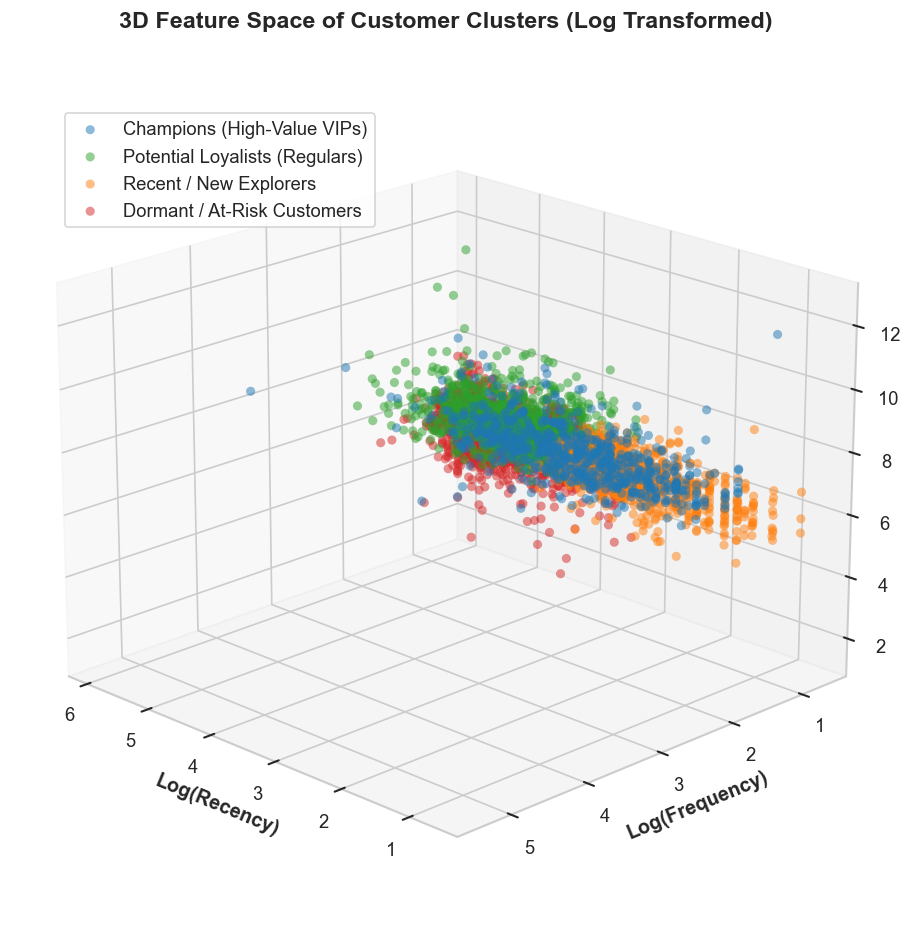

In [15]:
# Visualization 4: 3D Cluster Visualization
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
colors_map = {
    'Champions (High-Value VIPs)': '#1f77b4',
    'Potential Loyalists (Regulars)': '#2ca02c',
    'Recent / New Explorers': '#ff7f0e',
    'Dormant / At-Risk Customers': '#d62728'
}

for name, col in colors_map.items():
    subset = rfm[rfm['Cluster_Name'] == name]
    ax.scatter(
        np.log1p(subset['Recency']),
        np.log1p(subset['Frequency']),
        np.log1p(subset['Monetary']),
        c=col,
        label=name,
        alpha=0.5,
        s=30,
        edgecolors='none'
    )

ax.set_title('3D Feature Space of Customer Clusters (Log Transformed)', pad=20, fontsize=14, fontweight='bold')
ax.set_xlabel('Log(Recency)')
ax.set_ylabel('Log(Frequency)')
ax.set_zlabel('Log(Monetary)')
ax.view_init(elev=20, azim=135)
ax.legend(loc='upper left', bbox_to_anchor=(0.05, 0.95))
fig.tight_layout()

# Save chart to outputs
plt.savefig(os.path.join(output_dir, 'cluster_3d_scatter.png'), dpi=300)
plt.show()


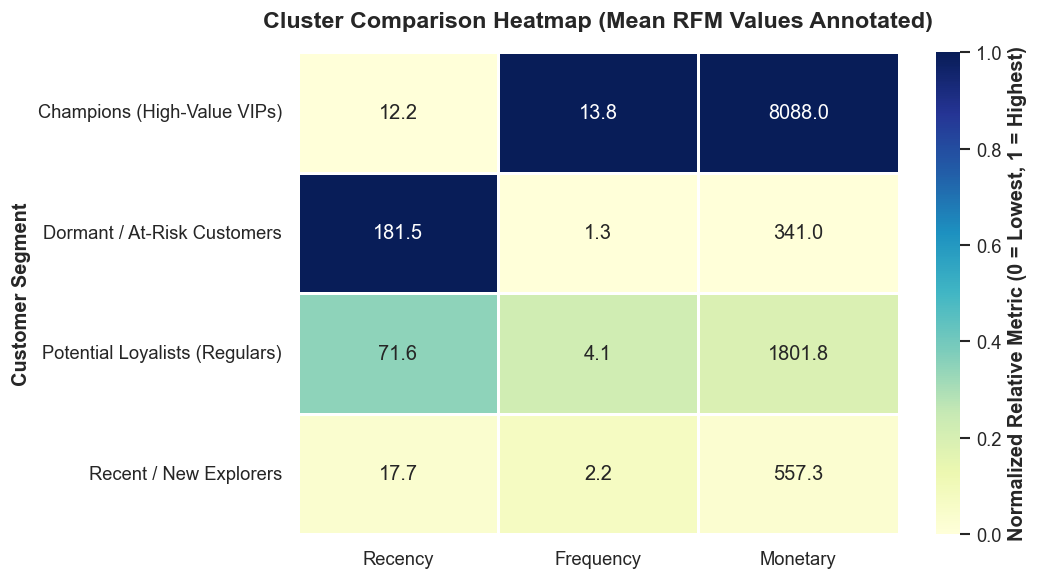

In [16]:
# Visualization 5: Normalized Cluster Centroids Heatmap
rfm_norm_profile = rfm.groupby('Cluster_Name')[['Recency', 'Frequency', 'Monetary']].mean()
rfm_norm = (rfm_norm_profile - rfm_norm_profile.min()) / (rfm_norm_profile.max() - rfm_norm_profile.min())

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(
    rfm_norm,
    annot=rfm_norm_profile.round(1),
    fmt=".1f",
    cmap='YlGnBu',
    linewidths=1.5,
    cbar_kws={'label': 'Normalized Relative Metric (0 = Lowest, 1 = Highest)'},
    ax=ax
)
ax.set_title('Cluster Comparison Heatmap (Mean RFM Values Annotated)', pad=15)
ax.set_ylabel('Customer Segment')
fig.tight_layout()

# Save chart to outputs
plt.savefig(os.path.join(output_dir, 'cluster_profiles_heatmap.png'), dpi=300)
plt.show()


### 🔍 Observations: Cluster Profiling Summary
1. **Champions (High-Value VIPs)**: 713 customers (16.4%) with exceptional metrics: **Recency = 12.2 days**, **Frequency = 13.8 orders**, and **Average Spend = $8,088.02**. They are the revenue backbone of the store.
2. **Potential Loyalists (Regulars)**: 1,166 customers (26.9%) with **Recency = 71.6 days**, **Frequency = 4.1 orders**, and **Average Spend = $1,801.78**. Consistent buyers with high conversion potential for VIP status.
3. **Recent / New Explorers**: 837 customers (19.3%) with very low recency (**17.7 days**), moderate frequency (**2.2 orders**), and **Average Spend = $557.32**. Fresh customers in their initial buying lifecycle.
4. **Dormant / At-Risk Customers**: 1,622 customers (37.4%) with high recency (**181.5 days**), single purchases (**1.3 orders**), and low spend (**$341.00**). High churn probability.
---
## 🎯 11. Actionable Marketing Recommendations & Segment Personas

### 1. Champions (High-Value VIPs) — Strategy: *White-Glove Retention & Advocacy*
- **Persona**: Frequent high-spenders buying on a bi-weekly cadence.
- **Action**: Enroll in an invite-only VIP Concierge Program with dedicated account managers, sneak previews of new product launches, and zero-fee expedited shipping.
- **Campaign**: Automated replenishment reminders and personalized loyalty gifting rather than heavy price discounting.

### 2. Potential Loyalists (Regulars) — Strategy: *Cross-Selling & Basket Expansion*
- **Persona**: Regular customers with proven commitment who have not yet reached top-tier spend.
- **Action**: Introduce category cross-sell recommendations (e.g. "Frequently Bought Together") and threshold incentive promotions (e.g. "Spend $250+ to unlock 15% off next purchase").
- **Campaign**: Loyalty milestone challenges to motivate moving from 4 orders to 8+ orders annually.

### 3. Recent / New Explorers — Strategy: *Onboarding & Second-Purchase Acceleration*
- **Persona**: Buyers who completed an order within the last 3 weeks but have only made 1–2 lifetime purchases.
- **Action**: Deploy a 3-part automated email onboarding sequence: Order follow-up + Product care tips + 14-day second-order discount voucher.
- **Campaign**: Survey them on satisfaction and offer points bonuses for review submissions to accelerate their next purchase.

### 4. Dormant / At-Risk Customers — Strategy: *Targeted Win-Back & List Scrubbing*
- **Persona**: Disengaged customers with >6 months of inactivity and minimal lifetime spend.
- **Action**: Launch a multi-stage "We Miss You" win-back campaign with aggressive time-limited vouchers (e.g., 25% off) and "What did we miss?" feedback forms.
- **Campaign**: Suppress unengaged contacts after 3 attempts to preserve email sender reputation and reduce marketing waste.

---
## 🏁 Conclusion
This project successfully translated 541,909 raw e-commerce transaction lines into a mathematically robust, 4-tier customer segmentation model using RFM feature engineering and $K$-Means clustering. The resulting personas empower business stakeholders to optimize marketing ROI, prevent churn, and accelerate top-line revenue growth.